# Walmart — jak dobrze modele przewidziały sprzedaż?

Ocena na zbiorze testowym (ostatnie 8 tygodni, których model nie widział).
Predykcje są zapisywane automatycznie przez `run_experiments` do `results/predykcje/`,
więc ten notatnik niczego nie trenuje — tylko wczytuje i rysuje.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from src.config import setup_style
from src.data import load_raw, clean
from src.experiment import load_results, load_preds, best_per_family, plot_heatmap, RESULTS_CSV, PREDS_DIR
from src import plots

setup_style()
df_clean = clean(load_raw(), verbose=False)
res = load_results()
print(f'{RESULTS_CSV.name}: {len(res)} wyników, {res["dane"].nunique()} wariantów danych, '
      f'zmieniony {pd.Timestamp(RESULTS_CSV.stat().st_mtime, unit="s"):%Y-%m-%d %H:%M}')
print(f'Pliki predykcji: {len(list(PREDS_DIR.glob("*.csv")))}')

eksperymenty.csv: 66 wyników, 6 wariantów danych, zmieniony 2026-11-25 18:08
Pliki predykcji: 66


## 1. Wybór modeli do porównania

Domyślnie: wariant danych z najlepszym WMAE i w nim najlepsza wersja każdej rodziny
(XGBoost, LightGBM, sieć, średnia) - dzięki temu notatnik pokazuje aktualne wyniki po każdym
przebiegu `run_all.py`. Można nadpisać ręcznie, np. `DANE = 'bazowy'`, `WYBRANE = ['XGBoost (strojony)']`
(nazwy jak w `results/eksperymenty.csv`, kolumny `dane`, `model`).

In [2]:
DANE = res.loc[res['WMAE'].idxmin(), 'dane']
WYBRANE = best_per_family(res, DANE)
print('Wariant danych:', DANE, '| modele:', WYBRANE)

preds = {m: load_preds(DANE, m) for m in WYBRANE}
plots.summary(preds).round(3)

Wariant danych: rozszerzone | modele: ['Średnia XGB+LGBM+Sieć', 'LightGBM-L1 (strojony, 5 ziaren)', 'XGBoost-L1 (strojony, 5 ziaren)', 'Sieć z embeddingami-reszta (strojony, 10 ziaren)']


,WMAE,MAE,RMSE,R2,błąd sumy tyg. %
model,,,,,
Średnia XGB+LGBM+Sieć,1133.918,1063.166,2293.428,0.989,1.150
"LightGBM-L1 (strojony, 5 ziaren)",1136.965,1069.906,2347.020,0.988,1.457
"XGBoost-L1 (strojony, 5 ziaren)",1149.493,1074.529,2337.425,0.988,1.430
"Sieć z embeddingami-reszta (strojony, 10 ziaren)",1168.164,1103.035,2284.685,0.989,1.398


`błąd sumy tyg. %` — o ile procent średnio myli się prognoza **łącznej** sprzedaży sieci w tygodniu
(błędy pojedynczych działów częściowo się znoszą, więc ta liczba jest zwykle dużo mniejsza niż MAE/średnia).

## 2. Łączna sprzedaż sieci: rzeczywista vs prognoza

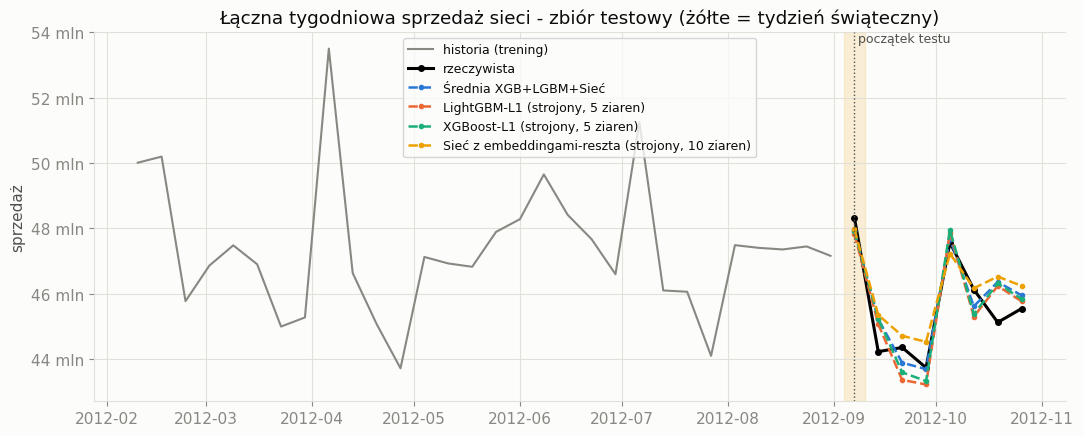

In [3]:
plots.plot_total(preds, history=df_clean)
plt.tight_layout(); plt.show()

## 3. Przykładowe działy w sklepach

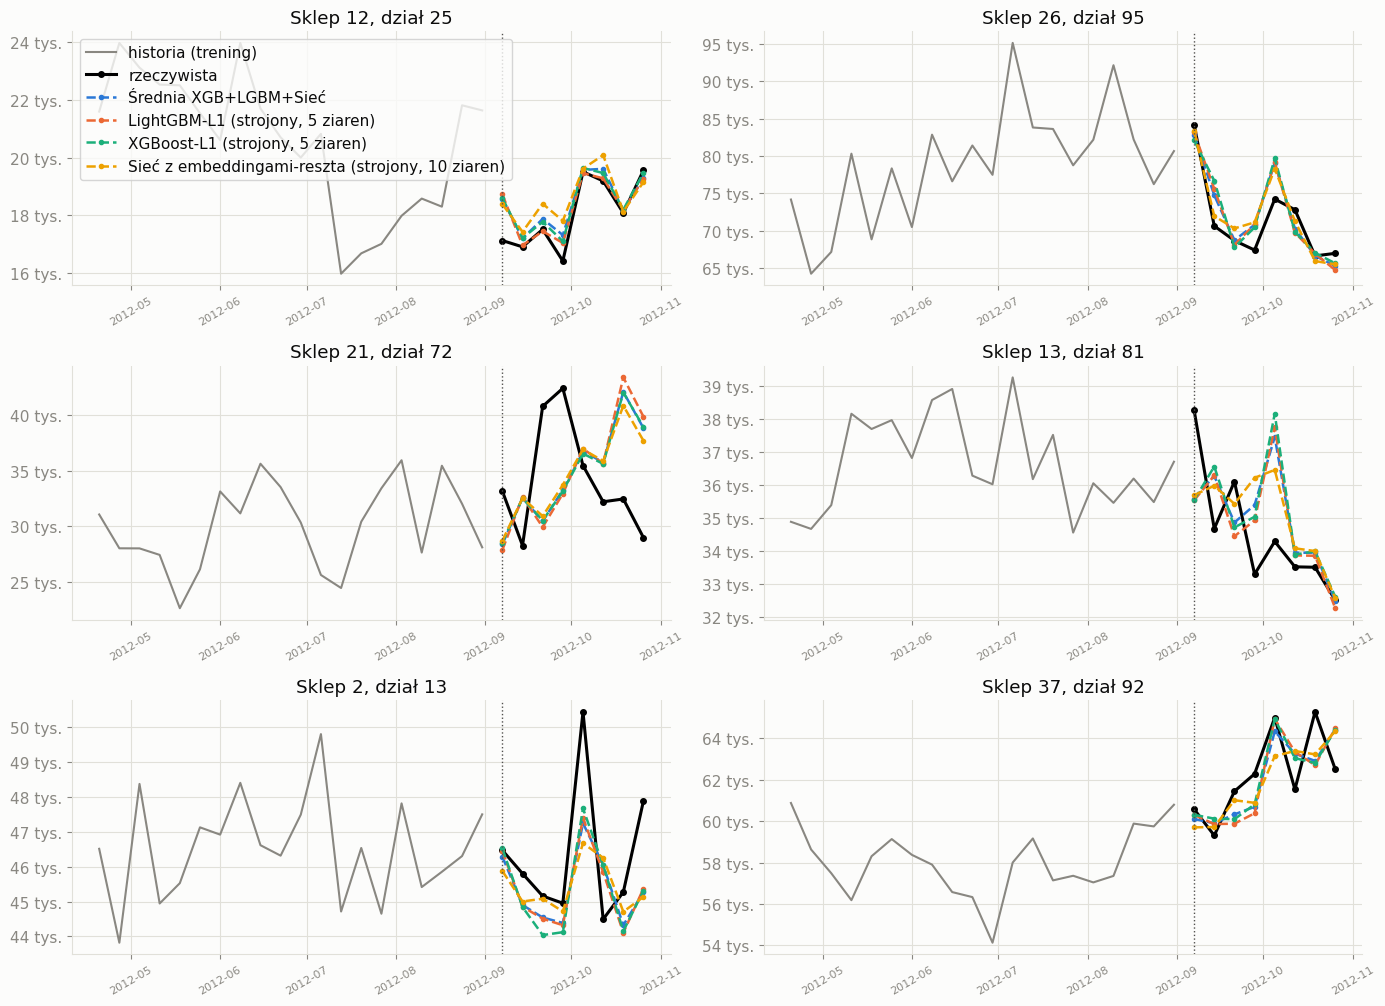

In [4]:
plots.plot_examples(preds, history=df_clean, n=6, seed=0)   # zmień seed -> inne przykłady
plt.show()

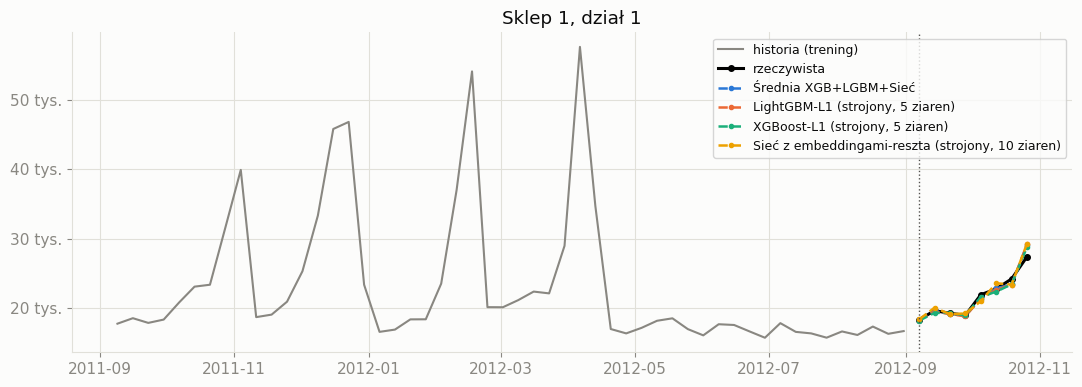

In [5]:
# Konkretny sklep i dział
plots.plot_series(preds, store=1, dept=1, history=df_clean)
plt.tight_layout(); plt.show()

## 4. Przewidziana vs rzeczywista (każdy punkt = sklep × dział × tydzień)

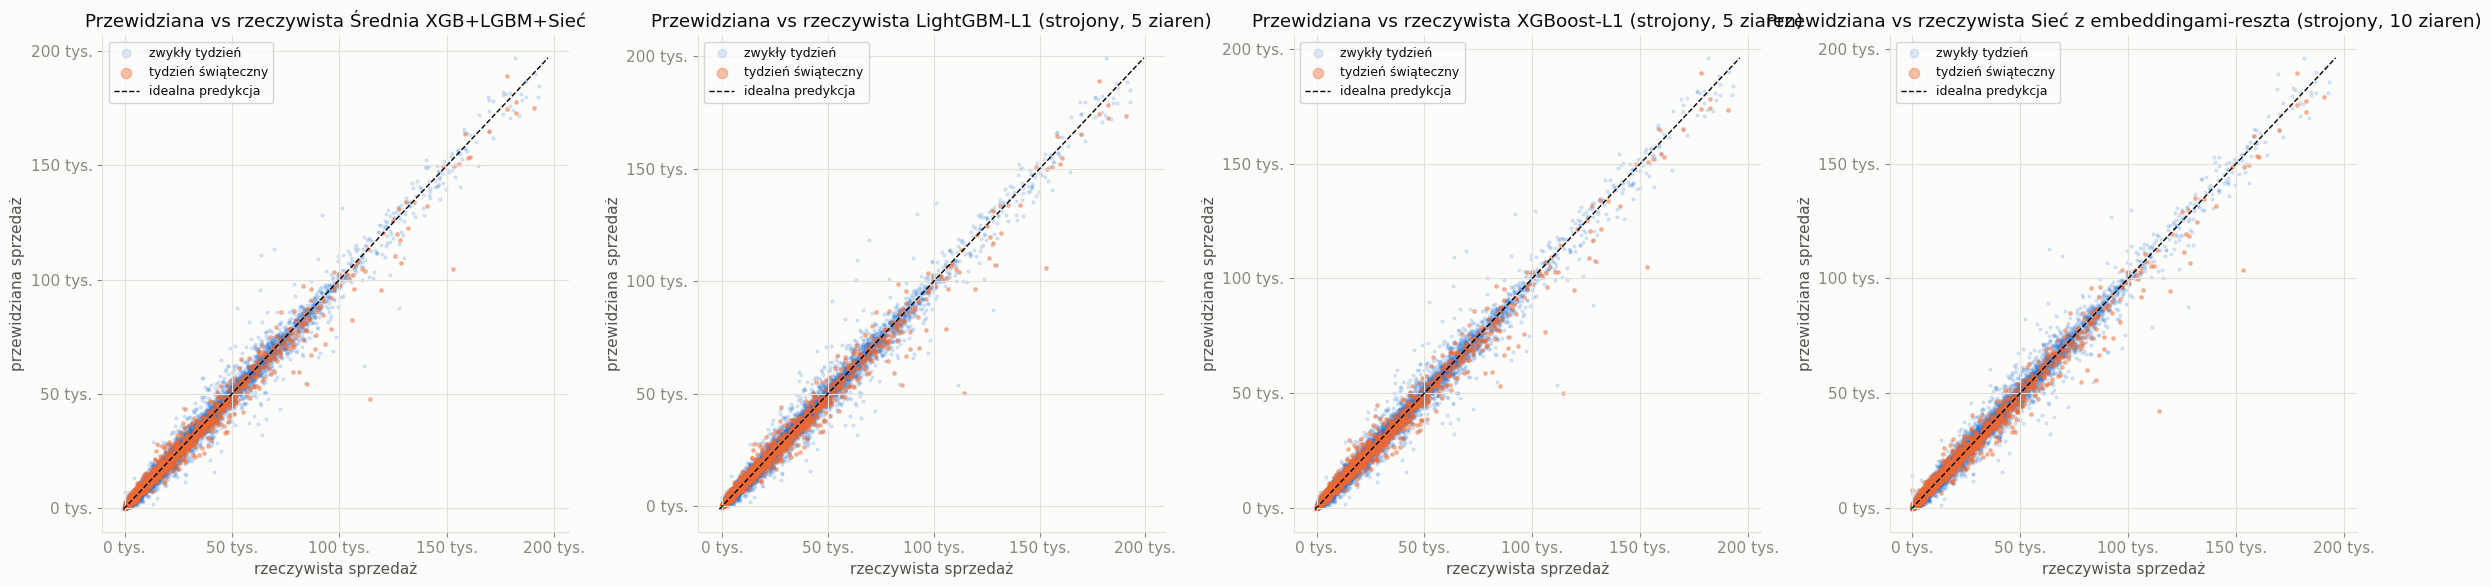

In [6]:
fig, axes = plt.subplots(1, len(preds), figsize=(6 * len(preds), 6), squeeze=False)
for ax, (name, p) in zip(axes[0], preds.items()):
    plots.plot_scatter(p, name, ax=ax)
plt.tight_layout(); plt.show()

## 5. Błędy: rozkład, w czasie, gdzie model myli się najbardziej

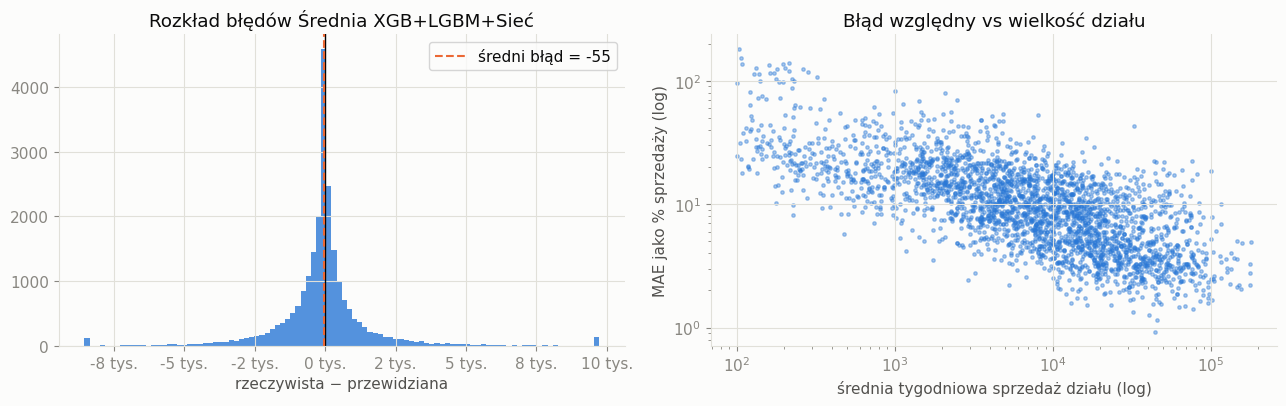

In [7]:
best = plots.summary(preds).index[0]
plots.plot_errors(preds[best], best)
plt.show()

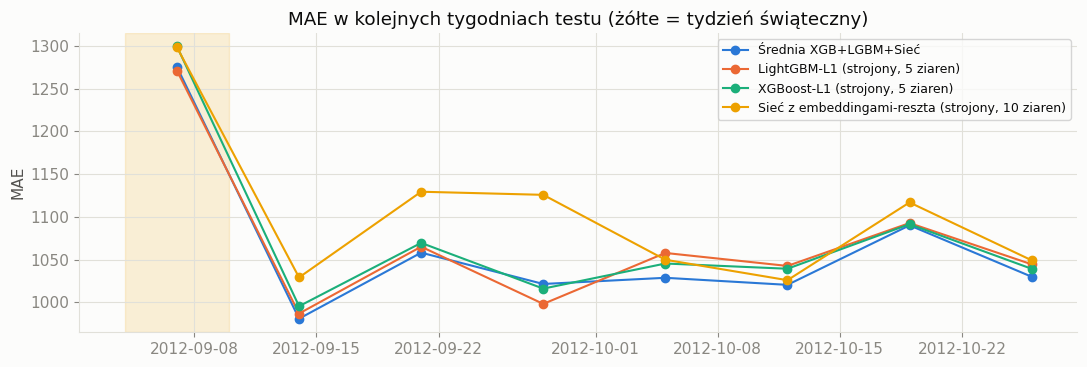

In [8]:
plots.plot_error_by_week(preds)
plt.tight_layout(); plt.show()

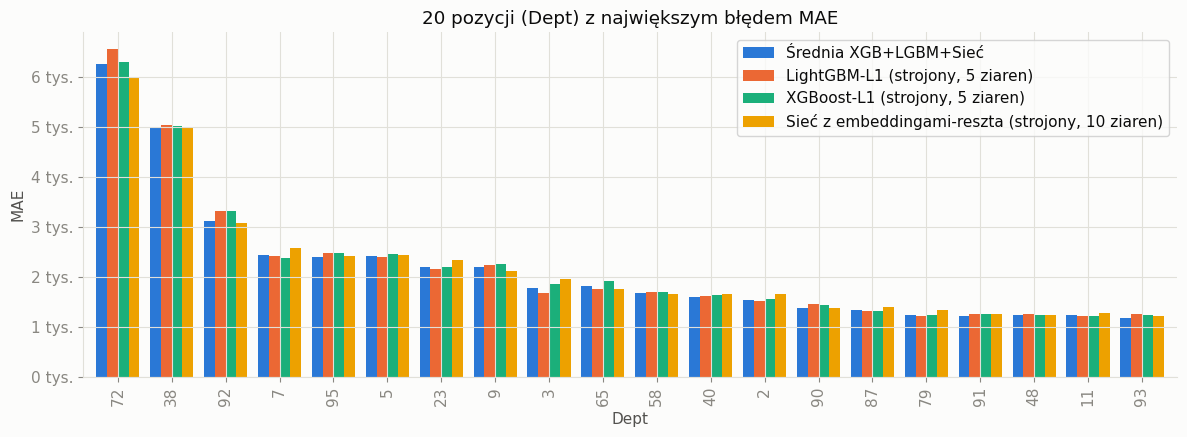

In [9]:
plots.plot_error_by(preds, by='Dept', top=20)
plt.tight_layout(); plt.show()

## 6. Wszystkie modele i warianty danych

In [10]:
cols = ['dane', 'model', 'WMAE', 'MAE', 'RMSE', 'R2', 'czas_s']
res.sort_values('WMAE')[cols].head(20).reset_index(drop=True)

,dane,model,WMAE,MAE,RMSE,R2,czas_s
0,rozszerzone,Średnia XGB+LGBM+Sieć,1133.918124,1063.165979,2293.427617,0.988920,1161.7
1,rozszerzone,"LightGBM-L1 (strojony, 5 ziaren)",1136.964849,1069.906123,2347.019779,0.988396,212.9
2,rozszerzone,LightGBM-L1 (strojony),1144.798126,1074.285543,2340.767319,0.988458,42.9
3,dodatkowe_lagi,Średnia XGB+LGBM+Sieć,1147.329625,1074.185231,2298.246693,0.988874,2327.9
4,rozszerzone,"XGBoost-L1 (strojony, 5 ziaren)",1149.492764,1074.528568,2337.425060,0.988491,308.9
5,rozszerzone,LightGBM-L1,1149.609292,1090.360744,2398.039874,0.987886,18.4
6,rozszerzone,XGBoost-L1 (strojony),1155.848656,1080.090507,2345.238653,0.988414,61.8
7,rozszerzone,XGBoost-L1,1164.141441,1097.704968,2373.337256,0.988135,34.0
8,rozszerzone,XGBoost,1167.012877,1109.200973,2365.278802,0.988215,27.1
9,rozszerzone,"Sieć z embeddingami-reszta (strojony, 10 ziaren)",1168.163528,1103.035026,2284.684946,0.989005,639.9


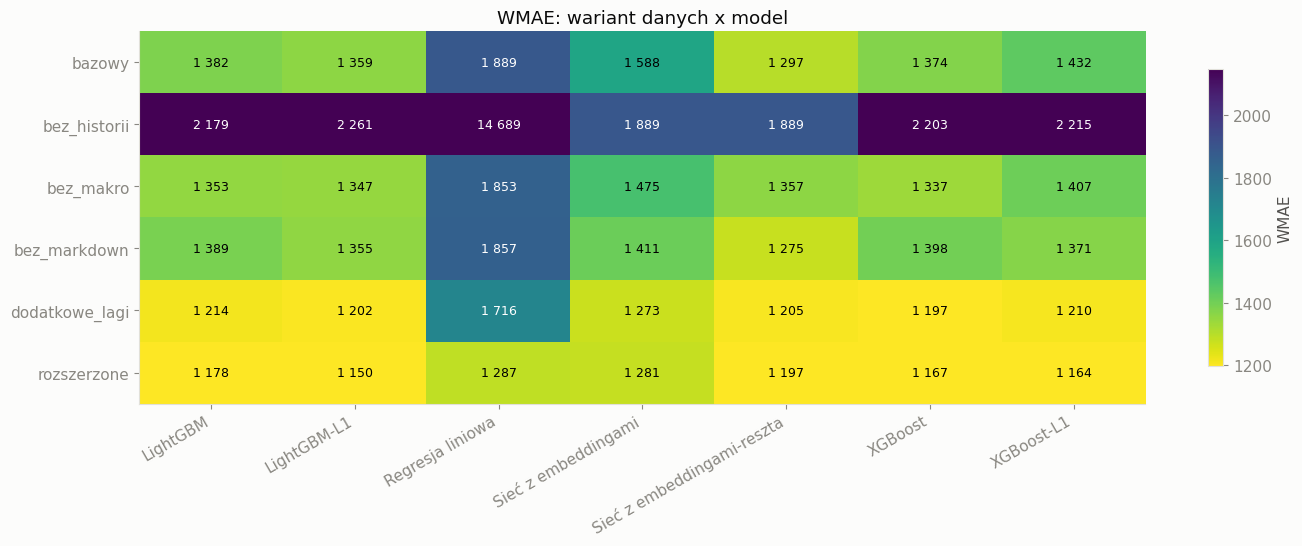

In [11]:
# tylko modele z siatki (bez wersji strojonych i średnich) - każdy policzony na każdym wariancie
grid = res[~res['model'].str.contains(r'strojony|Średnia')]
plot_heatmap(grid, 'WMAE')
plt.tight_layout(); plt.show()

## 7. Co dały strojenie, uśrednianie ziaren i średnia modeli?

Wszystkie wersje modeli w wariancie `DANE`. `model bazowy` to wersja z domyślnymi parametrami
(np. `XGBoost-L1` dla `XGBoost-L1 (strojony, 5 ziaren)`). `zysk vs bazowy` mówi, o ile spadł WMAE
względem tego modelu bazowego (wartość ujemna oznacza pogorszenie). Dla średniej porównaniem jest
najlepszy pojedynczy model w wariancie.

In [12]:
r = res[(res['dane'] == DANE) & (res['model'] != 'Regresja liniowa')].copy()
r['model bazowy'] = r['model'].str.replace(r' \(.*\)$', '', regex=True)
wmae = r.set_index('model')['WMAE']
is_avg = r['model'].str.startswith('Średnia')
r['zysk vs bazowy'] = r['model bazowy'].map(wmae) - r['WMAE']
r.loc[is_avg, 'model bazowy'] = '(najlepszy pojedynczy)'
r.loc[is_avg, 'zysk vs bazowy'] = wmae[~wmae.index.str.startswith('Średnia')].min() - r.loc[is_avg, 'WMAE']
r.sort_values(['model bazowy', 'WMAE'])[['model bazowy', 'model', 'WMAE', 'zysk vs bazowy', 'R2', 'czas_s']]     .round({'WMAE': 1, 'zysk vs bazowy': 1, 'R2': 4, 'czas_s': 1}).reset_index(drop=True)

,model bazowy,model,WMAE,zysk vs bazowy,R2,czas_s
0,(najlepszy pojedynczy),Średnia XGB+LGBM+Sieć,1133.9,3.0,0.9889,1161.7
1,LightGBM,LightGBM,1178.0,0.0,0.9878,12.7
2,LightGBM-L1,"LightGBM-L1 (strojony, 5 ziaren)",1137.0,12.6,0.9884,212.9
3,LightGBM-L1,LightGBM-L1 (strojony),1144.8,4.8,0.9885,42.9
4,LightGBM-L1,LightGBM-L1,1149.6,0.0,0.9879,18.4
5,Sieć z embeddingami,Sieć z embeddingami,1281.3,0.0,0.9871,26.9
6,Sieć z embeddingami-reszta,"Sieć z embeddingami-reszta (strojony, 10 ziaren)",1168.2,28.7,0.9890,639.9
7,Sieć z embeddingami-reszta,Sieć z embeddingami-reszta (strojony),1183.7,13.2,0.9881,30.4
8,Sieć z embeddingami-reszta,Sieć z embeddingami-reszta,1196.8,0.0,0.9886,34.9
9,XGBoost,XGBoost,1167.0,0.0,0.9882,27.1


## 8. Zapisane najlepsze modele (`models/najlepsze/`)

Top 5 według WMAE, zapisane przez `src/best.py` po każdym przebiegu `run_all.py`. `WMAE_ponowny_trening`
to wynik po ponownym wytrenowaniu przed zapisem i powinien być równy `WMAE`. Pliki powyżej 95 MB są
tylko lokalnie (`w_gicie = False`).

In [13]:
from pathlib import Path
ranking = pd.read_csv(Path('models/najlepsze/ranking.csv'))
ranking[['dane', 'model', 'WMAE', 'WMAE_ponowny_trening', 'R2', 'plik', 'rozmiar_MB', 'w_gicie']].round({'WMAE': 1, 'R2': 4})

,dane,model,WMAE,WMAE_ponowny_trening,R2,plik,rozmiar_MB,w_gicie
0,rozszerzone,Średnia XGB+LGBM+Sieć,1133.9,1133.92,0.9889,01__rozszerzone__Średnia_XGB+LGBM+Sieć.joblib,528.4,False
1,rozszerzone,"LightGBM-L1 (strojony, 5 ziaren)",1137.0,1136.96,0.9884,"02__rozszerzone__LightGBM-L1_(strojony,_5_ziar...",160.4,False
2,rozszerzone,LightGBM-L1 (strojony),1144.8,1144.80,0.9885,03__rozszerzone__LightGBM-L1_(strojony).joblib,32.1,True
3,dodatkowe_lagi,Średnia XGB+LGBM+Sieć,1147.3,1147.33,0.9889,04__dodatkowe_lagi__Średnia_XGB+LGBM+Sieć.joblib,1312.8,False
4,rozszerzone,"XGBoost-L1 (strojony, 5 ziaren)",1149.5,1149.49,0.9885,"05__rozszerzone__XGBoost-L1_(strojony,_5_ziare...",359.9,False
